<h1 align="center"><b>Hands-on workshop:Using Omic Tools for Target Selection.</b></h1>

<p align="center">
⚕ ⏭ ⛏ ⏭ 🎯 ⏭ ⚛ ⏭ 🤖 ⏭ ⚕

---



<p align="center">
  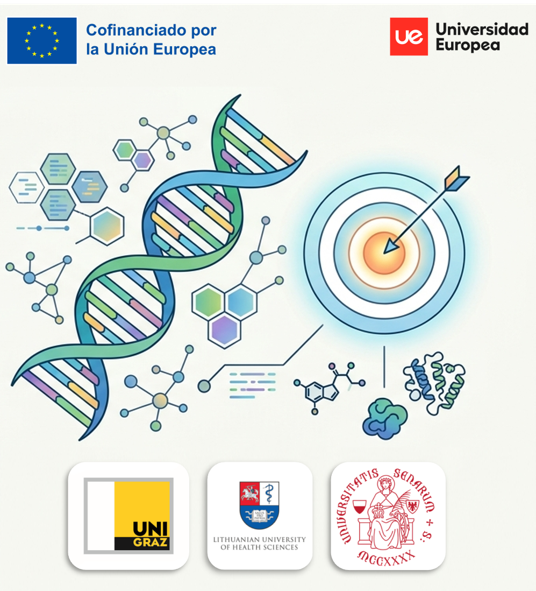
</p>

# Interactive GWAS Data Exploration

**A guided, reproducible workflow for GWAS Catalog associations and full summary statistics**

This notebook is designed as a learning resource. Each section explains what the code does, why the step matters, and how to explore the results.



## Learning objectives

By the end, you will be able to:

1. Download GWAS data from the GWAS Catalog and keep a reproducible local copy.
2. Inspect, validate, and clean tabular genetic-association data.
3. Parse chromosome and base-pair coordinates and construct a Manhattan plot.
4. Explore genes, risk alleles, chromosomes, annotations, and p-values interactively.
5. Build a Q-Q plot to compare observed and expected p-values.

> **Important interpretation note:** a GWAS association is statistical evidence, not proof that a variant causes a trait. A p-value threshold is a screening convention, not a measure of biological effect size. Interpret every result in the context of the study design, ancestry, sample size, and phenotype definition.

## 1. Set up the analysis environment.

In [1]:
#@markdown We use **pandas** to work with tables, **NumPy** for numerical calculations, **Plotly** for zoomable charts and hover details, and **ipywidgets** for filters that update results in the notebook.

#@markdown If dependencies are missing, run `%pip install pandas numpy requests plotly ipywidgets` in a separate cell, then restart the kernel and run all cells again. In Google Colab, the widget manager is enabled automatically by the setup cell.

# Import libraries for downloading, cleaning, analysing, and visualising the data.
from pathlib import Path
import os
import requests
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from IPython.display import display, Markdown, clear_output

# Choose a Plotly renderer that matches the notebook interface.
# Google Colab needs its widget manager enabled explicitly for ipywidgets controls.
try:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
    pio.renderers.default = "colab"
    NOTEBOOK_ENVIRONMENT = "Google Colab"
except Exception:
    # VS Code has its own renderer; most Jupyter frontends support the Plotly MIME renderer.
    if "VSCODE_PID" in os.environ or "VSCODE_CWD" in os.environ:
        pio.renderers.default = "vscode"
        NOTEBOOK_ENVIRONMENT = "VS Code notebook"
    else:
        pio.renderers.default = "plotly_mimetype"
        NOTEBOOK_ENVIRONMENT = "Jupyter-compatible notebook"

# Widgets are optional. If the import fails, later cells use ordinary tables and charts.
try:
    import ipywidgets as widgets
    WIDGETS_AVAILABLE = True
except ImportError:
    widgets = None
    WIDGETS_AVAILABLE = False
    print("ipywidgets is not installed. Install it with %pip install ipywidgets to use dashboard controls.")

# Keep this True for dropdowns, sliders, and live-updating outputs.
# Set it to False if your notebook frontend does not support widget controls.
USE_WIDGET_CONTROLS = WIDGETS_AVAILABLE

# Use a dedicated folder so downloaded source files do not get mixed with notebook code.
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Show enough columns when reviewing data, without forcing very long text fields to wrap.
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 140)

# Keep random selections reproducible if a later analysis uses sampling.
RANDOM_SEED = 42

print(f"Notebook environment: {NOTEBOOK_ENVIRONMENT}")
print(f"Plotly renderer: {pio.renderers.default}")
print(f"pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"ipywidgets installed: {WIDGETS_AVAILABLE}")
print(f"Widget controls enabled: {USE_WIDGET_CONTROLS}")


def check_visual_output():
    """Display a tiny test table and Plotly chart to diagnose notebook rendering."""
    display(Markdown("### Visual output check\nIf the table and chart below appear, pandas and Plotly output rendering is working."))
    display(pd.DataFrame({"Test row": [1, 2, 3], "Example value": [10, 20, 30]}))
    test_figure = go.Figure(
        data=go.Scatter(x=[1, 2, 3], y=[1, 4, 2], mode="lines+markers", name="Test data")
    )
    test_figure.update_layout(
        title="Plotly rendering test",
        xaxis_title="Example X",
        yaxis_title="Example Y",
        template="plotly_white",
        height=350,
    )
    display(test_figure)
    if WIDGETS_AVAILABLE:
        display(Markdown("**Widget test:** the slider below should be visible if the frontend supports ipywidgets."))
        display(widgets.IntSlider(value=5, min=0, max=10, description="Test slider:"))
    else:
        print("Widget test skipped because ipywidgets could not be imported.")


Notebook environment: Google Colab
Plotly renderer: colab
pandas version: 2.2.3
NumPy version: 2.1.3
ipywidgets installed: True
Widget controls enabled: True


## 2. Download the GWAS Catalog association export

The first dataset contains curated associations for the EFO trait identifier `EFO_0004319`, including associations annotated to child traits. The URL and parameters are kept in named variables so the query is easy to inspect or change.

The helper below downloads a file only when a usable local copy is not already present. It writes to a temporary file first, so an interrupted download is less likely to leave a partial file that looks complete.

Reference: [GWAS Catalog REST API v2 documentation](https://www.ebi.ac.uk/gwas/docs/programmatic-access/rest-api/).

In [ ]:
# This endpoint returns the curated associations for the selected EFO trait.
EFO_TRAIT = "" #@param {type:"string"}

ASSOCIATIONS_URL = (
    f"https://www.ebi.ac.uk/gwas/api/v2/efotraits/{EFO_TRAIT}/associations/download"
    "?includeBgTraits=false&includeChildTraits=true"
)
ASSOCIATIONS_PATH = DATA_DIR / f"{EFO_TRAIT}_AssociationExport.tsv"


def download_if_missing(url: str, destination: Path, *, overwrite: bool = False) -> Path:
    """Download a URL to a local file, reusing a valid existing file by default."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    # Reuse a non-empty local copy so rerunning the notebook does not repeatedly download data.
    if destination.exists() and destination.stat().st_size > 0 and not overwrite:
        print(f"Using existing file: {destination} ({destination.stat().st_size:,} bytes)")
        return destination

    # Stream the response to disk to avoid holding a large download in memory.
    temporary_path = destination.with_name(destination.name + ".part")
    try:
        with requests.get(url, stream=True, timeout=(20, 180)) as response:
            response.raise_for_status()
            with temporary_path.open("wb") as output_file:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        output_file.write(chunk)
        # Replace the destination only after the download has completed successfully.
        temporary_path.replace(destination)
    except Exception:
        # Remove an incomplete temporary file before passing the error back to the learner.
        temporary_path.unlink(missing_ok=True)
        raise

    print(f"Downloaded: {destination} ({destination.stat().st_size:,} bytes)")
    return destination


# Download the curated association export. Set overwrite=True when you deliberately need a fresh copy.
download_if_missing(ASSOCIATIONS_URL, ASSOCIATIONS_PATH)

## 3. Load the source data and inspect its structure

In [ ]:
#@markdown Before cleaning anything, inspect the table. This helps you understand what one row represents, which columns are available, and whether the downloaded file has the expected structure.

#@markdown The original source column names are preserved because they are part of the GWAS Catalog data format.

# Read the tab-separated export into a DataFrame; TSV files use a tab as the field separator.
associations_raw = pd.read_csv(ASSOCIATIONS_PATH, sep="\t", low_memory=False)

# Report the dimensions before cleaning, so we can quantify how many records are retained later.
print(f"Raw rows: {len(associations_raw):,}")
print(f"Raw columns: {associations_raw.shape[1]:,}")

# Display the column names and data types to identify fields that may need conversion.
display(pd.DataFrame({
    "column": associations_raw.columns,
    "data_type": associations_raw.dtypes.astype(str).values,
}))

# Preview a few records instead of printing the entire dataset to the screen.
display(associations_raw.head(5))

## 4. Clean the association data and parse genomic coordinates

In [ ]:
#@markdown For the Manhattan plot, we need three valid pieces of information: a p-value, a chromosome, and a base-pair position. The `locations` field commonly stores coordinates in a form such as `3:3638168` or `chr3:3638168`.

#@markdown This step:

#@markdown - converts p-values and positions to numeric values;
#@markdown - extracts chromosome and position from `locations`;
#@markdown - keeps autosomes 1–22 for the conventional autosomal Manhattan plot;
#@markdown - keeps p-values in the valid range from 0 to 1;
#@markdown - preserves the original descriptive columns for later exploration.

#@markdown We do **not** permanently filter to `p ≤ 0.05` here. Keeping all valid p-values makes it possible to change the significance threshold interactively later.

#@markdown A p-value stored as exactly zero is generally a numerical/reporting limit, not a literal probability of zero. The raw value is retained; only the logarithmic display uses a small positive floor.

def clean_catalog_associations(source_df: pd.DataFrame) -> pd.DataFrame:
    """Validate GWAS Catalog fields and add numeric chromosome/position columns."""
    # Make a copy so cleaning never mutates the original source table.
    cleaned = source_df.copy()

    # Check the minimum fields needed for this workflow and fail with a useful explanation.
    required_columns = {"pValue", "locations"}
    missing_columns = required_columns.difference(cleaned.columns)
    if missing_columns:
        raise ValueError(f"The association export is missing required columns: {sorted(missing_columns)}")

    # Convert p-values to numbers; invalid text becomes NaN and is removed in the next step.
    cleaned["pValue"] = pd.to_numeric(cleaned["pValue"], errors="coerce")
    cleaned = cleaned.loc[cleaned["pValue"].between(0, 1, inclusive="both")].copy()

    # Extract the first chromosome:position pair, allowing an optional 'chr' prefix.
    # String extraction handles examples such as '3:3638168' and 'chr3:3638168'.
    coordinate_parts = cleaned["locations"].astype("string").str.extract(
        r"(?i)(?:chr)?(?P<CHR>\d{1,2})\s*:\s*(?P<BP>\d+)"
    )
    cleaned["CHR"] = pd.to_numeric(coordinate_parts["CHR"], errors="coerce")
    cleaned["BP"] = pd.to_numeric(coordinate_parts["BP"], errors="coerce")

    # Remove rows without parseable coordinates before converting to integer columns.
    cleaned = cleaned.dropna(subset=["CHR", "BP"]).copy()
    cleaned["CHR"] = cleaned["CHR"].astype(int)
    cleaned["BP"] = cleaned["BP"].astype("int64")

    # Keep chromosomes 1–22 for the standard autosomal Manhattan plot.
    cleaned = cleaned.loc[cleaned["CHR"].between(1, 22)].copy()

    # Use concise internal names for repeated calculations while keeping all source columns.
    cleaned = cleaned.rename(columns={"pValue": "P"})
    cleaned["LOGP"] = -np.log10(cleaned["P"].clip(lower=np.finfo(float).tiny))

    # Sort rows for predictable previews and downstream summaries.
    cleaned = cleaned.sort_values(["CHR", "BP"], kind="stable").reset_index(drop=True)
    return cleaned


associations = clean_catalog_associations(associations_raw)

# Summarise the impact of cleaning so the data loss is transparent.
print(f"Rows in source export: {len(associations_raw):,}")
print(f"Rows retained for autosomal analysis: {len(associations):,}")
print(f"Rows removed: {len(associations_raw) - len(associations):,}")
print(f"Chromosomes represented: {associations['CHR'].nunique()}")
print(f"P-values reported as zero (clipped only for log display): {(associations['P'] == 0).sum():,}")

display(associations.head(10))

## 5. Create continuous genome coordinates for a Manhattan plot

In [ ]:
#@markdown Chromosome positions restart at zero on each chromosome. If we used raw base-pair positions, the chromosomes would overlap on the x-axis. We therefore calculate a cumulative position by adding the lengths of preceding chromosomes.

#@markdown The plotted height is `−log10(p-value)`: smaller p-values appear higher on the chart. The dashed reference line marks the conventional genome-wide significance threshold of `5 × 10⁻⁸`. Use hover details, zoom, and pan to inspect points.

def add_cumulative_coordinates(
    data: pd.DataFrame,
    chromosome_column: str = "CHR",
    position_column: str = "BP",
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Add cumulative genomic positions and return chromosome tick locations."""
    # Sort chromosomes numerically so chromosome 10 follows chromosome 9, not chromosome 1.
    result = data.copy()
    chromosome_lengths = (
        result.groupby(chromosome_column)[position_column]
        .max()
        .sort_index()
    )

    # Each chromosome starts after the maximum observed position of all preceding chromosomes.
    chromosome_offsets = chromosome_lengths.shift(1, fill_value=0).cumsum()
    result["CHROM_OFFSET"] = result[chromosome_column].map(chromosome_offsets)
    result["CUM_POS"] = result[position_column] + result["CHROM_OFFSET"]

    # Put each chromosome label at the midpoint of its observed coordinate range.
    chromosome_centers = pd.DataFrame({
        chromosome_column: chromosome_lengths.index.to_numpy(),
        "CENTER": (chromosome_offsets + chromosome_lengths / 2).to_numpy(),
    }).reset_index(drop=True)
    return result, chromosome_centers


associations, association_chromosome_centers = add_cumulative_coordinates(associations)

# Quickly inspect the cumulative coordinates before drawing the full chart.
display(association_chromosome_centers.head(10))

## 6. Interactive Manhattan plot and association browser

In [ ]:
#@markdown Use the controls to change the p-value threshold, focus on one chromosome, or search for a gene. The table below the chart updates with the same filters. Hover over chart points to see their coordinates, p-values, genes, and trait labels.

#@markdown **About point limits:** rendering hundreds of thousands of markers can make a notebook slow. When necessary, the plotting helper keeps a reproducible spread of genomic positions and also retains the strongest associations.

# Pick the best available descriptive columns so the hover labels work across export versions.
CATALOG_GENE_COLUMN = "mappedGenes" if "mappedGenes" in associations.columns else None
CATALOG_TRAIT_COLUMN = "traitName" if "traitName" in associations.columns else None


def limit_plot_points(data: pd.DataFrame, max_points: int = 50_000, p_column: str = "P") -> pd.DataFrame:
    """Limit chart markers while retaining both genomic coverage and the smallest p-values."""
    if len(data) <= max_points:
        return data

    # Use roughly half the budget to represent the whole genome from left to right.
    ordered = data.sort_values(["CHR", "BP"], kind="stable")
    spread_count = max(1, max_points // 2)
    spread_indices = np.linspace(0, len(ordered) - 1, num=spread_count, dtype=int)
    genome_spread = ordered.iloc[spread_indices]

    # Use the remaining budget for the strongest p-values, which are scientifically interesting.
    strongest = data.nsmallest(max_points - spread_count, p_column)

    # Remove duplicates because a very significant point may also appear in the genome-wide sample.
    limited = pd.concat([genome_spread, strongest]).drop_duplicates()
    return limited.sort_values(["CHR", "BP"], kind="stable")


def build_manhattan_figure(
    data: pd.DataFrame,
    chromosome_centers: pd.DataFrame,
    *,
    p_column: str,
    threshold: float,
    title: str,
    gene_column: str | None = None,
    detail_column: str | None = None,
    max_points: int = 50_000,
) -> go.Figure:
    """Build a hover-enabled Manhattan plot from data with cumulative coordinates."""
    # Limit only the markers sent to the browser; summaries and tables keep the full filtered data.
    plot_data = limit_plot_points(data, max_points=max_points, p_column=p_column)
    figure = go.Figure()

    # Alternate colours by chromosome to make neighbouring chromosome blocks easier to distinguish.
    chromosome_colors = {chromosome: ("#2B5C8F" if chromosome % 2 else "#7AA6D6")
                         for chromosome in range(1, 23)}

    for chromosome, chromosome_data in plot_data.groupby("CHR", sort=True):
        # Prepare informative but compact hover text, allowing for optional columns in the source.
        gene_values = (chromosome_data[gene_column].fillna("Not available").astype(str)
                       if gene_column and gene_column in chromosome_data.columns
                       else pd.Series("Not available", index=chromosome_data.index))
        detail_values = (chromosome_data[detail_column].fillna("Not available").astype(str)
                         if detail_column and detail_column in chromosome_data.columns
                         else pd.Series("Not available", index=chromosome_data.index))
        p_values_for_hover = chromosome_data[p_column].map(lambda value: f"{value:.3e}")
        custom_data = np.column_stack([
            chromosome_data["CHR"].astype(str),
            chromosome_data["BP"].astype(str),
            p_values_for_hover.astype(str),
            gene_values.astype(str),
            detail_values.astype(str),
        ])

        # One WebGL trace per chromosome keeps the chart responsive for large point clouds.
        figure.add_trace(go.Scattergl(
            x=chromosome_data["CUM_POS"],
            y=chromosome_data["LOGP"],
            mode="markers",
            name=f"Chr {chromosome}",
            marker={"color": chromosome_colors.get(int(chromosome), "#777777"),
                    "size": 5, "opacity": 0.72},
            customdata=custom_data,
            hovertemplate=(
                "Chromosome: %{customdata[0]}<br>"
                "Position: %{customdata[1]} bp<br>"
                "P-value: %{customdata[2]}<br>"
                "Gene / variant ID: %{customdata[3]}<br>"
                "Trait / annotation: %{customdata[4]}<br>"
                "−log10(p): %{y:.2f}<extra></extra>"
            ),
            showlegend=False,
        ))

    # Draw the selected threshold as a reference line when it is more restrictive than p = 1.
    if 0 < threshold < 1:
        figure.add_hline(
            y=-np.log10(threshold),
            line_dash="dash",
            line_color="#B22222",
            annotation_text=f"p = {threshold:.1e}",
            annotation_position="top left",
        )

    # Put chromosome numbers at their cumulative midpoint positions.
    figure.update_layout(
        title=title,
        template="plotly_white",
        height=520,
        margin={"l": 65, "r": 25, "t": 75, "b": 65},
        xaxis_title="Chromosome",
        yaxis_title="−log10(p-value)",
        hovermode="closest",
    )
    figure.update_xaxes(
        tickmode="array",
        tickvals=chromosome_centers["CENTER"],
        ticktext=chromosome_centers["CHR"].astype(str),
        showgrid=False,
    )
    figure.update_yaxes(rangemode="tozero", gridcolor="rgba(100,100,100,0.18)")
    return figure


# These threshold labels will be reused across the interactive dashboards.
P_VALUE_THRESHOLDS = {
    "All valid p-values (p ≤ 1)": 1.0,
    "Nominal significance (p ≤ 0.05)": 0.05,
    "Suggestive (p ≤ 1e-5)": 1e-5,
    "Genome-wide (p ≤ 5e-8)": 5e-8,
}


def show_catalog_dashboard(threshold_label, chromosome_choice, gene_search, max_points):
    """Render a table and Manhattan plot using the same student-controlled filters."""
    # Begin with the complete cleaned association table.
    filtered = associations.copy()
    threshold = P_VALUE_THRESHOLDS[threshold_label]

    # Apply the requested significance threshold before updating the table and chart.
    filtered = filtered.loc[filtered["P"] <= threshold].copy()

    # Optionally focus on one chromosome.
    if chromosome_choice != "All chromosomes":
        selected_chromosome = int(chromosome_choice)
        filtered = filtered.loc[filtered["CHR"] == selected_chromosome].copy()
        # Rebase the selected chromosome to start at zero so its points fill the chart instead of appearing far along the full-genome axis.
        filtered["CUM_POS"] = filtered["BP"]
        chromosome_length = associations.loc[
            associations["CHR"] == selected_chromosome, "BP"
        ].max()
        plot_centers = pd.DataFrame({
            "CHR": [selected_chromosome],
            "CENTER": [chromosome_length / 2],
        })
    else:
        # With all chromosomes selected, keep the cumulative genome-wide coordinates.
        plot_centers = association_chromosome_centers

    # Search within mapped gene names as plain text, not as a regular expression.
    if gene_search.strip() and CATALOG_GENE_COLUMN:
        filtered = filtered.loc[
            filtered[CATALOG_GENE_COLUMN].astype("string").str.contains(
                gene_search.strip(), case=False, regex=False, na=False
            )
        ].copy()

    # Sort by p-value so the most statistically significant rows appear first in the table.
    filtered = filtered.sort_values("P", ascending=True)
    display(Markdown(
        f"**Matching associations:** {len(filtered):,}  \n"
        f"**Smallest p-value:** {filtered['P'].min():.3e}" if not filtered.empty
        else "**Matching associations:** 0. Try a less restrictive threshold or clear the gene search."
    ))

    # Display only useful fields and at most 25 rows to keep the interactive output readable.
    preferred_columns = ["CHR", "BP", "P", CATALOG_GENE_COLUMN, CATALOG_TRAIT_COLUMN,
                         "riskAllele", "accessionId"]
    display_columns = [column for column in preferred_columns
                       if column and column in filtered.columns]
    display(filtered[display_columns].head(25))

    # Draw the chart only when at least one row remains after filtering.
    if not filtered.empty:
        figure = build_manhattan_figure(
            filtered,
            plot_centers,
            p_column="P",
            threshold=threshold,
            title="GWAS Catalog associations — interactive Manhattan plot",
            gene_column=CATALOG_GENE_COLUMN,
            detail_column=CATALOG_TRAIT_COLUMN,
            max_points=max_points,
        )
        display(figure)


if WIDGETS_AVAILABLE and USE_WIDGET_CONTROLS:
    # Dropdowns constrain inputs to valid choices and make exploration accessible to beginners.
    catalog_threshold_widget = widgets.Dropdown(
        options=list(P_VALUE_THRESHOLDS.keys()),
        value="Nominal significance (p ≤ 0.05)",
        description="P-value:",
        layout=widgets.Layout(width="420px"),
    )
    catalog_chromosome_widget = widgets.Dropdown(
        options=["All chromosomes"] + [str(value) for value in range(1, 23)],
        value="All chromosomes",
        description="Chromosome:",
        layout=widgets.Layout(width="260px"),
    )
    catalog_gene_widget = widgets.Text(
        value="",
        placeholder="For example, CHRNA4; leave blank for all genes",
        description="Gene:",
        layout=widgets.Layout(width="520px"),
    )
    catalog_max_points_widget = widgets.IntSlider(
        value=30_000, min=5_000, max=100_000, step=5_000,
        description="Plot points:", continuous_update=False,
        layout=widgets.Layout(width="520px"),
    )

    # Bind the controls to the same function so every change refreshes the table and chart together.
    catalog_dashboard_output = widgets.interactive_output(
        show_catalog_dashboard,
        {
            "threshold_label": catalog_threshold_widget,
            "chromosome_choice": catalog_chromosome_widget,
            "gene_search": catalog_gene_widget,
            "max_points": catalog_max_points_widget,
        },
    )
    display(widgets.VBox([
        widgets.HTML("<b>Explore the association export</b>"),
        widgets.HBox([catalog_threshold_widget, catalog_chromosome_widget]),
        catalog_gene_widget,
        catalog_max_points_widget,
    ]))
    display(catalog_dashboard_output)
else:
    # Static fallback: these outputs work even when the frontend cannot display widget controls.
    print("Showing the non-widget fallback. Plotly still supports hover, zoom, and pan.")
    fallback_columns = [column for column in [
        "CHR", "BP", "P", CATALOG_GENE_COLUMN, CATALOG_TRAIT_COLUMN, "riskAllele", "accessionId"
    ] if column and column in associations.columns]
    display(associations.sort_values("P")[fallback_columns].head(25))
    display(build_manhattan_figure(
        associations, association_chromosome_centers, p_column="P", threshold=5e-8,
        title="GWAS Catalog associations — non-widget Manhattan plot",
        gene_column=CATALOG_GENE_COLUMN, detail_column=CATALOG_TRAIT_COLUMN,
    ))


## 7. Compare genes and explore a gene of interest

In [ ]:
#@markdown A mean p-value by gene is usually not a useful summary: p-values are not effect sizes, and averaging them can hide a very strong association. Instead, the summary below reports the **number of associations** and the **smallest p-value** for each mapped gene.

#@markdown The gene explorer starts with `CHRNA4`, as in the original notebook. Try another gene symbol, or use part of a gene name. A match means the text appears anywhere in the `mappedGenes` field, so it may match multiple records.

if CATALOG_GENE_COLUMN:
    # Split multi-gene entries so each gene receives credit for each association where it is listed.
    gene_rows = associations[[CATALOG_GENE_COLUMN, "P"]].dropna(subset=[CATALOG_GENE_COLUMN]).copy()
    gene_rows["Gene"] = gene_rows[CATALOG_GENE_COLUMN].astype(str).str.split(r"[,;|]")
    gene_rows = gene_rows.explode("Gene")
    gene_rows["Gene"] = gene_rows["Gene"].astype(str).str.strip()

    # Remove empty placeholders and aggregate interpretable measures, not the mean p-value.
    gene_rows = gene_rows.loc[
        gene_rows["Gene"].ne("") & ~gene_rows["Gene"].str.lower().isin({"nan", "none", "-", "na"})
    ].copy()
    gene_summary = (
        gene_rows.groupby("Gene", as_index=False)
        .agg(Association_count=("P", "size"), Best_P_value=("P", "min"))
        .sort_values(["Association_count", "Best_P_value"], ascending=[False, True])
    )

    # A horizontal bar chart makes the most frequently mapped genes easier to compare.
    top_genes = gene_summary.head(20).sort_values("Association_count", ascending=True)
    gene_figure = px.bar(
        top_genes,
        x="Association_count",
        y="Gene",
        orientation="h",
        hover_data={"Best_P_value": ":.3e", "Association_count": True},
        title="Top 20 mapped genes by number of catalog associations",
        labels={"Association_count": "Number of associations", "Gene": "Mapped gene"},
    )
    gene_figure.update_layout(template="plotly_white", height=600)
    display(gene_figure)
    display(gene_summary.head(20))
else:
    print("The mappedGenes field is not present in this version of the association export.")

In [ ]:
Gene_name = "" #@param {type:"string"}

def show_gene_details(gene_query: str = Gene_name) -> None:
    """Display association records and risk alleles matching a gene search."""
    if not CATALOG_GENE_COLUMN:
        print("This export does not contain a mappedGenes column.")
        return

    # Search case-insensitively so the gene symbol can be entered in either upper or lower case.
    matches = associations.loc[
        associations[CATALOG_GENE_COLUMN].astype("string").str.contains(
            gene_query.strip(), case=False, regex=False, na=False
        )
    ].sort_values("P")

    print(f"Search term: {gene_query!r}")
    print(f"Matching association rows: {len(matches):,}")

    # Show unique risk alleles separately from the full table to make the key field easy to find.
    if "riskAllele" in matches.columns:
        risk_alleles = sorted(matches["riskAllele"].dropna().astype(str).unique())
        print("Unique risk alleles:", risk_alleles if risk_alleles else "None recorded")

    # Present a compact set of columns and limit the preview while retaining all matches in memory.
    detail_columns = [column for column in [
        "CHR", "BP", "P", CATALOG_GENE_COLUMN, CATALOG_TRAIT_COLUMN,
        "riskAllele", "riskFrequency", "orValue", "beta", "accessionId", "author"
    ] if column and column in matches.columns]
    display(matches[detail_columns].head(50))


if WIDGETS_AVAILABLE and USE_WIDGET_CONTROLS:
    gene_query_widget = widgets.Text(
        value=Gene_name,
        description="Gene search:",
        placeholder="Enter any gene symbol",
        layout=widgets.Layout(width="480px"),
    )
    gene_details_output = widgets.interactive_output(
        show_gene_details,
        {"gene_query": gene_query_widget},
    )
    display(gene_query_widget, gene_details_output)
else:
    show_gene_details(Gene_name)

## 8. Download full summary statistics for study `GCST007460`

The association export above is a curated set of reported associations. Full summary statistics are a different resource and can contain millions of variants, including variants that are not statistically significant.

This section downloads the study file as a compressed `.txt.gz` file and reads only the columns needed for the analyses below. Keeping the compressed source file avoids an unnecessary decompression step and makes reruns more reproducible.

The file path follows the GWAS Catalog's documented summary-statistics directory pattern. If the study's file name or location changes, check the study page or the [GWAS Catalog summary statistics documentation](https://www.ebi.ac.uk/gwas/docs/methods/summary-statistics/).

In [ ]:
# URL= "https://ftp.ebi.ac.uk/pub/databases/gwas/summary_statistics/GCST007001-GCST008000/GCST007460/SmokingCessation.txt.gz" #@param {type:"string"}
# Study_id = "GCST007460" #@param {type:"string"}
# Study_name= "SmokingCessation.txt.gz" #@param {type:"string"}



URL= "" #@param {type:"string"}

Study_id = "" #@param {type:"string"}

Study_name= "" #@param {type:"string"}

Study_name = Study_name+".txt.gz"

SUMMARY_STATS_URL = (URL)

SUMMARY_STATS_PATH = DATA_DIR / Study_id / Study_name

# This may be a large file; set overwrite=True only when you intentionally want to download it again.
download_if_missing(SUMMARY_STATS_URL, SUMMARY_STATS_PATH)

## 9. Load, validate, and filter the full summary statistics

In [ ]:
#@markdown We first inspect the file header, then load only columns that exist and are needed by this notebook. This reduces memory use compared with reading every available field.

#@markdown The code keeps the original `CHROM`, `POS`, `PVALUE`, `ANNO`, and `ANNOFULL` column names. It also handles a file that does not contain every optional annotation field, while clearly reporting which fields are available.

def load_summary_statistics(path: Path) -> pd.DataFrame:
    """Load only the available summary-statistics columns required by this notebook."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"Summary-statistics file not found: {path}. Run the download cell above first."
        )

    # Read only the header so we can request columns that actually exist in this study's file.
    available_columns = pd.read_csv(path, sep="\t", nrows=0, compression="infer").columns.tolist()
    required_columns = {"CHROM", "POS", "PVALUE"}
    missing_required = required_columns.difference(available_columns)
    if missing_required:
        raise ValueError(
            f"The summary-statistics file is missing required columns: {sorted(missing_required)}. "
            f"Available columns include: {available_columns[:30]}"
        )

    # Annotation columns are useful but optional; include only the fields present in the source file.
    preferred_columns = [
        "CHROM", "POS", "PVALUE", "ANNO", "ANNOFULL", "RSID", "SNPID", "ID"
    ]
    columns_to_load = [column for column in preferred_columns if column in available_columns]

    # Let pandas read the gzip file directly, avoiding a separate file-decompression command.
    data = pd.read_csv(
        path,
        sep="\t",
        usecols=columns_to_load,
        compression="infer",
        low_memory=False,
    )

    # Convert numerical columns explicitly so downstream filters do not depend on inferred dtypes.
    data["POS"] = pd.to_numeric(data["POS"], errors="coerce")
    data["PVALUE"] = pd.to_numeric(data["PVALUE"], errors="coerce")
    data = data.loc[data["POS"].notna() & data["PVALUE"].between(0, 1, inclusive="both")].copy()
    data["POS"] = data["POS"].astype("int64")

    # Standardise chromosome labels for filtering while preserving the original CHROM field values.
    data["CHROM"] = (
        data["CHROM"].astype(str).str.strip().str.replace(r"(?i)^chr", "", regex=True)
    )
    return data.reset_index(drop=True)


summary_stats = load_summary_statistics(SUMMARY_STATS_PATH)

print(f"Usable summary-statistics rows: {len(summary_stats):,}")
print("Available columns:", list(summary_stats.columns))
display(summary_stats.head(5))
display(summary_stats[["CHROM", "POS", "PVALUE"]].describe(include="all"))

## 10. Inspect annotations and chromosome 20

The original workflow removes rows whose full annotation contains `Intergenic`, then focuses on chromosome 20. We keep both the complete loaded table and a filtered copy so that the effect of the filter can be compared rather than hidden.

If `ANNOFULL` is not provided by this particular file, the code falls back to `ANNO` when available. Check the displayed annotation field before interpreting the result.

In [ ]:
chromosome = ""  # @param {type:"string"}

# Prefer the detailed annotation field, but fall back to the shorter field if required.
if "ANNOFULL" in summary_stats.columns:
    annotation_column = "ANNOFULL"
elif "ANNO" in summary_stats.columns:
    annotation_column = "ANNO"
else:
    annotation_column = None

if annotation_column:
    # Keep rows whose annotation does not contain the Intergenic label, ignoring letter case.
    is_intergenic = summary_stats[annotation_column].astype("string").str.contains(
        "Intergenic", case=False, na=False
    )
    summary_stats_non_intergenic = summary_stats.loc[~is_intergenic].copy()
    print(f"Annotation field used: {annotation_column}")
    print(f"Rows before annotation filter: {len(summary_stats):,}")
    print(f"Rows after removing intergenic annotations: {len(summary_stats_non_intergenic):,}")
else:
    # If no annotation field exists, keep all records and explain why no annotation filter was applied.
    summary_stats_non_intergenic = summary_stats.copy()
    print("No ANNOFULL or ANNO column was found; no intergenic filter was applied.")

# Select chromosome 20 as a separate view without modifying the broader filtered dataset.
summary_stats_chr20 = summary_stats_non_intergenic.loc[
    summary_stats_non_intergenic["CHROM"].eq(chromosome)
].copy()
print(f"Rows on chromosome {chromosome} after filtering: {len(summary_stats_chr20):,}")
display(summary_stats_chr20.head(10))

## 11. Q-Q plot: observed versus expected p-values

In [ ]:
#@markdown A Q-Q plot compares the distribution of observed p-values with what would be expected under a uniform null distribution. The diagonal represents agreement between observed and expected values.

#@markdown Points above the diagonal indicate more small p-values than expected under the null, but this can reflect true associations, confounding, population structure, technical artefacts, or a mixture of these. A Q-Q plot alone cannot determine the cause.

#@markdown For speed, the chart displays evenly spaced points from the sorted p-value distribution when the dataset is very large. The number of variants used to calculate the ranks remains the full number of valid p-values.

#@markdown ### Plot points
#@markdown Use this slider to control the maximum number of points displayed in the chart.
#@markdown
#@markdown The default value is **20,000 points**, and the slider allows you to choose between **2,000 and 50,000 points**.
#@markdown
#@markdown Try changing the slider and observe the following:
#@markdown * **Detail:** Increasing the limit may reveal more detail in the distribution, particularly near the extreme tail.
#@markdown * **Performance:** Decreasing the limit generally produces a lighter visualization that may respond more quickly.
#@markdown * **Consistency:** The overall pattern should remain broadly similar when the underlying distribution is stable, although some detail may be lost when fewer points are displayed.
#@markdown
#@markdown > **Important:** This slider does not change the underlying p-values, apply a significance threshold, or remove variants from the statistical analysis. It only changes how many points are drawn.


def build_qq_figure(p_values: pd.Series, max_points: int = 50_000) -> go.Figure:
    """Build a Q-Q plot from valid p-values, sampling chart markers evenly if needed."""
    # Convert to numeric and remove missing, invalid, or impossible p-values before ranking.
    valid_p = pd.to_numeric(p_values, errors="coerce").dropna().to_numpy(dtype=float)
    valid_p = valid_p[np.isfinite(valid_p) & (valid_p > 0) & (valid_p <= 1)]
    n = len(valid_p)
    if n == 0:
        raise ValueError("No valid p-values are available for the Q-Q plot.")

    # Sort largest to smallest so both -log10(expected p) and -log10(observed p) increase together.
    observed_p_sorted = np.sort(valid_p)[::-1]
    expected_p_sorted = np.arange(n, 0, -1, dtype=float) / (n + 1)
    observed = -np.log10(observed_p_sorted)
    expected = -np.log10(expected_p_sorted)

    # Sample across the complete sorted distribution so the plot remains responsive on large studies.
    if n > max_points:
        selected_indices = np.linspace(0, n - 1, num=max_points, dtype=int)
        expected = expected[selected_indices]
        observed = observed[selected_indices]
        observed_p_sorted = observed_p_sorted[selected_indices]

    # Set the diagonal length from the displayed data, and avoid a misleading unequal axis scale.
    axis_max = max(float(np.max(expected)), float(np.max(observed)), 1.0)
    figure = go.Figure()
    figure.add_trace(go.Scattergl(
        x=expected,
        y=observed,
        mode="markers",
        name="Observed variants",
        marker={"size": 5, "opacity": 0.55, "color": "#2B5C8F"},
        customdata=observed_p_sorted,
        hovertemplate=(
            "Expected −log10(p): %{x:.2f}<br>"
            "Observed −log10(p): %{y:.2f}<br>"
            "Observed p-value: %{customdata:.3e}<extra></extra>"
        ),
    ))
    figure.add_trace(go.Scatter(
        x=[0, axis_max], y=[0, axis_max], mode="lines", name="Null expectation",
        line={"color": "#B22222", "width": 2, "dash": "dash"},
        hoverinfo="skip",
    ))
    figure.update_layout(
        title=f"GWAS Q-Q plot ({n:,} valid p-values; {min(n, max_points):,} points displayed)",
        template="plotly_white",
        height=600,
        xaxis_title="Expected −log10(p-value)",
        yaxis_title="Observed −log10(p-value)",
        margin={"l": 75, "r": 30, "t": 75, "b": 70},
    )
    figure.update_xaxes(range=[0, axis_max], scaleanchor="y", scaleratio=1)
    figure.update_yaxes(range=[0, axis_max])
    return figure


if WIDGETS_AVAILABLE and USE_WIDGET_CONTROLS:
    qq_points_widget = widgets.IntSlider(
        value=40_000, min=5_000, max=100_000, step=5_000,
        description="Displayed points:", continuous_update=False,
        layout=widgets.Layout(width="520px"),
    )

    def update_qq(max_points):
        # Redraw the chart when the displayed point budget changes; statistical ranks still use all valid values.
        display(build_qq_figure(summary_stats["PVALUE"], max_points=max_points))

    qq_output = widgets.interactive_output(update_qq, {"max_points": qq_points_widget})
    display(qq_points_widget, qq_output)
else:
    display(build_qq_figure(summary_stats["PVALUE"], max_points=40_000))

### How to interpret the Q–Q plot

The most important feature of the Q–Q plot is the relationship between the points and the diagonal reference line.

**Pattern A — Points follow the diagonal**

When most points lie close to the diagonal, the observed p-value distribution is broadly consistent with the null expectation across that part of the distribution.

This does not necessarily mean that no genuine genetic associations exist. A small number of associations may be present without substantially changing the overall pattern.

**Pattern B — Points rise above the diagonal in the tail**

When points rise above the diagonal, their observed (-\log_{10}(p)) values are larger than expected. This means the observed p-values are smaller than expected under the null distribution.

An upward deviation concentrated in the extreme tail may indicate genuine genetic associations.

However, a similar pattern can result from population stratification, relatedness, technical artefacts, or other sources of test-statistic inflation.

The Q–Q plot alone cannot determine which explanation is correct.

**Pattern C — Broad deviation from the diagonal**

When the points systematically deviate from the diagonal across a substantial part of the distribution, the results may indicate widespread genetic associations or a problem with statistical calibration.

Additional analyses, such as genomic inflation factor assessment, linkage-disequilibrium-aware methods, and checks of population structure, may help distinguish these possibilities.

The precise interpretation depends on the study design, the number of participants, the trait architecture, and the statistical methods used.


**Why does the tail matter?**

The extreme tail contains the smallest observed p-values and often provides the strongest statistical evidence of association.

Zooming into this region can help you identify departures from the null expectation that are less apparent in the main distribution.

However, an extreme p-value is not by itself proof that a genetic variant causes a trait or disease.

## 12. Interactive Manhattan plot for full summary statistics

In [ ]:
#@markdown This Manhattan plot uses the full study-level summary statistics rather than only curated Catalog associations. The filters let you choose an annotation, chromosome, p-value threshold, and marker budget.

#@markdown Chromosomes 1–22 are included in this conventional plot. Other chromosome labels remain in `summary_stats`; they are not deleted from the source table. The intergenic filter can be reconsidered by switching the input from `summary_stats_non_intergenic` to `summary_stats` below.

def prepare_summary_for_manhattan(source_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Prepare full summary statistics for an autosomal Manhattan plot."""
    # Work with a copy so this plotting-specific transformation does not overwrite source fields.
    plot_data = source_df.copy()

    # Convert chromosome and coordinate fields and discard records that cannot be placed on the genome.
    plot_data["CHR"] = pd.to_numeric(plot_data["CHROM"], errors="coerce")
    plot_data["BP"] = pd.to_numeric(plot_data["POS"], errors="coerce")
    plot_data["PVALUE"] = pd.to_numeric(plot_data["PVALUE"], errors="coerce")
    plot_data = plot_data.dropna(subset=["CHR", "BP", "PVALUE"]).copy()
    plot_data = plot_data.loc[
        plot_data["CHR"].between(1, 22)
        & plot_data["BP"].gt(0)
        & plot_data["PVALUE"].between(0, 1, inclusive="both")
    ].copy()
    plot_data["CHR"] = plot_data["CHR"].astype(int)
    plot_data["BP"] = plot_data["BP"].astype("int64")

    # Replace zero only for the logarithmic transformation; retain the source PVALUE unchanged.
    plot_data["LOGP"] = -np.log10(plot_data["PVALUE"].clip(lower=np.finfo(float).tiny))

    # Add genome-wide x coordinates and chromosome tick locations using the same helper as above.
    plot_data, centers = add_cumulative_coordinates(plot_data, "CHR", "BP")
    plot_data = plot_data.sort_values(["CHR", "BP"], kind="stable").reset_index(drop=True)
    return plot_data, centers


summary_manhattan_data, summary_chromosome_centers = prepare_summary_for_manhattan(
    summary_stats_non_intergenic
)
print(f"Autosomal variants available for the Manhattan plot: {len(summary_manhattan_data):,}")
print(f"Chromosomes represented: {summary_manhattan_data['CHR'].nunique()}")

In [ ]:
#@markdown # Dashboard Controls
#@markdown The dashboard contains **four controls**. Changing any of them automatically updates the analysis and redraws the plot.
#@markdown
#@markdown ### 1. Annotation
#@markdown Use this dropdown to select a functional annotation category or choose *All annotations*.
#@markdown * **Analysis:** Try comparing the Manhattan plots for different annotation categories. Consider whether the distribution of association signals changes when you focus on variants in different functional contexts.
#@markdown * **Note:** Remember that an annotation category is not the same as a gene name. Selecting an annotation does not directly search for a specific gene such as *CHRNA4*.
#@markdown
#@markdown ### 2. Chromosome
#@markdown Choose *All chromosomes* to explore the genome-wide distribution of associations, or select an individual chromosome to focus on a specific genomic region.
#@markdown * **Analysis:** Compare the overall pattern with the distribution observed on a single chromosome. Do particularly strong association signals appear concentrated in certain regions?
#@markdown
#@markdown ### 3. P-value
#@markdown Use this dropdown to change the statistical significance threshold.
#@markdown * **Behavior:** A stringent threshold retains only variants with strong statistical evidence. A less stringent threshold includes more variants and may reveal additional patterns, although some of these associations may represent weaker evidence.
#@markdown * **Observation:** Observe how the number of retained variants and the appearance of the Manhattan plot change as you modify the threshold.
#@markdown
#@markdown ### 4. Plot points
#markdown Use this slider to control the maximum number of points displayed in the plot.
#@markdown * **Performance:** Increasing the limit can reveal more of the data, but may make the visualization slower, particularly for large datasets. Reducing the limit can improve responsiveness.


Annotation_number = None #@param {type:"number"}

# Limit annotation choices to the most common values if the file contains many categories.
if "ANNO" in summary_manhattan_data.columns:
    annotation_counts = summary_manhattan_data["ANNO"].fillna("Not annotated").value_counts()
    common_annotations = annotation_counts.head(Annotation_number).index.tolist()
else:
    common_annotations = []


def show_summary_dashboard(annotation_choice, chromosome_choice, threshold_label, max_points):
    """Filter summary statistics, display counts, and draw an interactive Manhattan plot."""
    # Begin from the autosomal plotting table; source summary_stats remains unchanged.
    filtered = summary_manhattan_data.copy()
    threshold = P_VALUE_THRESHOLDS[threshold_label]

    # Optionally focus on one functional annotation category.
    if annotation_choice != "All annotations" and "ANNO" in filtered.columns:
        filtered = filtered.loc[filtered["ANNO"].fillna("Not annotated").eq(annotation_choice)].copy()

    # Apply the p-value threshold before optional chromosome selection.
    filtered = filtered.loc[filtered["PVALUE"] <= threshold].copy()
    if chromosome_choice != "All chromosomes":
        selected_chromosome = int(chromosome_choice)
        filtered = filtered.loc[filtered["CHR"] == selected_chromosome].copy()
        # Rebase a single-chromosome view to its local base-pair positions for a readable axis.
        filtered["CUM_POS"] = filtered["BP"]
        chromosome_length = summary_manhattan_data.loc[
            summary_manhattan_data["CHR"] == selected_chromosome, "BP"
        ].max()
        plot_centers = pd.DataFrame({
            "CHR": [selected_chromosome],
            "CENTER": [chromosome_length / 2],
        })
    else:
        # Retain the continuous genome-wide axis when all chromosomes are shown.
        plot_centers = summary_chromosome_centers

    # Display a compact numeric summary before rendering the chart.
    print(f"Variants matching the selected filters: {len(filtered):,}")
    if filtered.empty:
        print("No variants match these filters. Try a less restrictive threshold or a different annotation.")
        return

    print(f"Smallest p-value in this view: {filtered['PVALUE'].min():.3e}")

    # Use the detailed annotation field, if available, as the second hover label.
    detail_column = "ANNOFULL" if "ANNOFULL" in filtered.columns else "ANNO"
    figure = build_manhattan_figure(
        filtered,
        plot_centers,
        p_column="PVALUE",
        threshold=threshold,
        title="Full summary statistics — interactive Manhattan plot",
        gene_column="RSID" if "RSID" in filtered.columns else ("SNPID" if "SNPID" in filtered.columns else None),
        detail_column=detail_column,
        max_points=max_points,
    )
    display(figure)


if WIDGETS_AVAILABLE and USE_WIDGET_CONTROLS:
    # Build annotation options from the available data while leaving all categories accessible in the table.
    annotation_options = [("All annotations", "All annotations")] + [
        (str(annotation), str(annotation)) for annotation in common_annotations
    ]
    summary_annotation_widget = widgets.Dropdown(
        options=annotation_options,
        value="All annotations",
        description="Annotation:",
        layout=widgets.Layout(width="420px"),
    )
    summary_chromosome_widget = widgets.Dropdown(
        options=["All chromosomes"] + [str(value) for value in range(1, 23)],
        value="All chromosomes",
        description="Chromosome:",
        layout=widgets.Layout(width="280px"),
    )
    summary_threshold_widget = widgets.Dropdown(
        options=list(P_VALUE_THRESHOLDS.keys()),
        value="Genome-wide (p ≤ 5e-8)",
        description="P-value:",
        layout=widgets.Layout(width="420px"),
    )
    summary_max_points_widget = widgets.IntSlider(
        value=40_000, min=5_000, max=100_000, step=5_000,
        description="Plot points:", continuous_update=False,
        layout=widgets.Layout(width="520px"),
    )

    # Any control change reruns the filtering and plotting function with the chosen values.
    summary_dashboard_output = widgets.interactive_output(
        show_summary_dashboard,
        {
            "annotation_choice": summary_annotation_widget,
            "chromosome_choice": summary_chromosome_widget,
            "threshold_label": summary_threshold_widget,
            "max_points": summary_max_points_widget,
        },
    )
    display(widgets.VBox([
        widgets.HTML("<b>Explore full summary statistics</b>"),
        widgets.HBox([summary_annotation_widget, summary_chromosome_widget]),
        summary_threshold_widget,
        summary_max_points_widget,
    ]))
    display(summary_dashboard_output)
else:
    # Static fallback: display data as well as the chart when interactive controls are unavailable.
    print("Showing the non-widget fallback. Plotly still supports hover, zoom, and pan.")
    display(summary_manhattan_data[[column for column in [
        "CHROM", "CHR", "BP", "PVALUE", "RSID", "SNPID", "ANNO"
    ] if column in summary_manhattan_data.columns]].head(25))
    display(build_manhattan_figure(
        summary_manhattan_data,
        summary_chromosome_centers,
        p_column="PVALUE",
        threshold=5e-8,
        title="Full summary statistics — non-widget Manhattan plot",
        gene_column="RSID" if "RSID" in summary_manhattan_data.columns else None,
        detail_column="ANNOFULL" if "ANNOFULL" in summary_manhattan_data.columns else "ANNO",
        max_points=40_000,
    ))


### How to interpret the Manhattan plot

Each point represents a genetic variant included in the filtered dataset.

* **X-axis:** The genomic position of each variant. When all chromosomes are displayed, the positions are arranged along the genome.

* **Y-axis:** The negative logarithm of the p-value, (-\log_{10}(p)). Higher points correspond to smaller p-values and stronger statistical evidence of association.

* **Horizontal significance line:** When shown, this indicates the selected p-value threshold. Points above the line meet that threshold.

* **Hover information:** Move your cursor over a point to inspect available variant identifiers and annotation details.

A cluster of high points may indicate a genomic region containing multiple strongly associated variants. However, nearby variants may be correlated because of linkage disequilibrium, so several associated points do not necessarily represent several independent genetic effects.

## 13. Student investigation prompts

Use the controls and tables to answer the following questions. Save your answers in a Markdown cell below this section.

1. How does the number of displayed associations change when you switch from `p ≤ 0.05` to the genome-wide threshold `p ≤ 5 × 10⁻⁸`?
2. Which gene has the largest number of mapped Catalog associations in this export? Does it also have the smallest p-value?
3. For `CHRNA4`, which risk alleles are listed, and do the rows refer to the same trait or to different traits?
4. In the Q-Q plot, where do the observed p-values begin to depart from the diagonal? What are at least two possible explanations for this departure?
5. How does the Manhattan plot change when you choose one annotation category or chromosome? Why should a chart filter not be confused with deleting rows from the source data?

### Reproducibility checklist

- Record the study accession, EFO identifier, download date, and any filters used in your analysis.
- Keep raw source data separate from cleaned or filtered DataFrames.
- Explain any thresholds chosen and do not interpret p-values as effect sizes.
- When sharing figures, include the phenotype, study identifier, significance line, and relevant filtering choices.